# 03 — Modelo de referência e baseline (Fase 3)

> **Aviso:** experimento didático com partição própria; não comparável ao benchmark oficial do MVTec AD.

Este notebook só lê `results/fase3/` (gerado por `python scripts/run_fase3.py`). A única parte que abre imagens é o exemplo visual opcional, no fim da seção 4.

## 1. Objetivo e pergunta

Construir o modelo do "normal" e a régua contra a qual todas as fases seguintes serão medidas (o baseline).

A garrafa é sempre fotografada de cima e centrada. Então "defeito" pode ser definido como desvio do padrão normal naquela posição:

$$z(x,y) = \frac{|I(x,y) - \mu(x,y)|}{\sigma(x,y) + \varepsilon}$$

com μ e σ por pixel estimados nas 120 boas de referência. Dividir por σ dá menos peso aos anéis, que variam naturalmente (Fase 1).

**Perguntas:**

1. Alinhar as garrafas por translação antes de montar a referência vale a pena?
2. O limiar precisa ser calibrado com garrafas boas, ou um Otsu no mapa z de cada imagem resolve?

## 2. Hipóteses e critérios (definidos antes do teste)

| | Hipótese | Critério de decisão |
|---|---|---|
| Alinhamento | A Fase 1 mediu até ~3 px de deslocamento do centro. Alinhar deve reduzir o desvio por pixel nos anéis, onde as bordas são nítidas, e quase não mexer no fundo. | Desvio por pixel nos anéis entre as boas de referência; AUROC de pixel no desenvolvimento. |
| Limiar | O Otsu sempre divide os valores em duas classes, mesmo quando não há defeito. Sem um modelo do normal, ele deve marcar pedaços de garrafas boas. O limiar calibrado (percentil de z nas boas) controla a taxa de falso positivo por construção. | Dice no desenvolvimento. |

Todas as decisões usam só o conjunto de desenvolvimento (9 imagens). Uma mudança por vez, o resto fixo.

## 3. O que foi feito

1. **Centro de cada garrafa:** `stats.object_disk` (Otsu separa garrafa escura × fundo branco; centroide por momentos; raio pela área).
2. **Alinhamento:** `reference.align_to` translada cada imagem para o centro médio da referência. `reference.translate` usa interpolação bilinear na imagem e vizinho mais próximo na máscara, para ela continuar binária.
3. **Modelo:** `reference.ReferenceModel.fit` calcula μ e σ por pixel nas 120 imagens de referência e a ROI (`reference.circular_roi`, disco com 95% do raio).
4. **Mapa z:** `ReferenceModel.anomaly_map`, zerado fora da ROI.
5. **Limiar do baseline:** percentil 99,5 de z dentro da ROI nas 30 boas de calibração.
6. **Variante Otsu:** `reference.otsu_threshold`, implementado à mão e conferido contra o OpenCV nos testes, aplicado ao mapa z de cada imagem.
7. **Métricas:** `metrics.image_metrics` e `metrics.summarize` (Dice, IoU, precisão e recall só dentro da ROI; nas boas, pixels falsos positivos e componentes espúrios).

Variantes comparadas: `baseline` (alinhado + limiar calibrado), `sem_alinhamento` e `otsu_por_imagem`.

In [ ]:
import pandas as pd
from IPython.display import Image, display
from pdi_defeitos import viz
from pdi_defeitos.config import load_config

cfg = load_config()
res = cfg['root'] / 'results' / 'fase3'

alin = pd.read_csv(res / 'alinhamento.csv')
auroc = pd.read_csv(res / 'auroc_pixel.csv')
resumo = pd.read_csv(res / 'resumo.csv')
por_imagem = pd.read_csv(res / 'metricas_por_imagem.csv')

VARIANTES = {'baseline': 'baseline (alinhado + limiar calibrado)', 'sem_alinhamento': 'sem alinhamento', 'otsu_por_imagem': 'Otsu por imagem'}
limiares = por_imagem[por_imagem.variante != 'otsu_por_imagem'].groupby('variante').limiar.first()
print('Parâmetros (config.yaml, seção reference):', cfg['reference'])
print('Limiar calibrado:', ', '.join(f'{VARIANTES[k]} = {viz.fmt_br(v)}' for k, v in limiares.items()))

Parâmetros (config.yaml, seção reference): {'align': True, 'roi_frac': 0.95, 'eps': 2.0, 'threshold_percentile': 99.5}
Limiar calibrado: baseline (alinhado + limiar calibrado) = 2,63, sem alinhamento = 2,72


## 4. Resultados

### 4.1 Efeito do alinhamento na variação natural

Desvio padrão por pixel entre as 120 boas de referência (níveis de cinza), no fundo da garrafa e nos anéis.

In [ ]:
t = alin.assign(alinhado=alin.alinhado.map({False: 'sem alinhamento', True: 'alinhado'})).set_index('alinhado')
mediana = t.pivot(columns='regiao', values='std_mediano')
p95 = t.pivot(columns='regiao', values='std_p95')
tab = pd.concat({'desvio mediano': mediana, 'percentil 95 do desvio': p95}, axis=1).loc[['sem alinhamento', 'alinhado']]
tab.index.name = None
queda = 100 * (1 - mediana.loc['alinhado'] / mediana.loc['sem alinhamento'])
print('Queda do desvio mediano com o alinhamento:', ', '.join(f'{k}: {viz.fmt_br(v, 1)}%' for k, v in queda.items()))
viz.fmt_table(tab)

Queda do desvio mediano com o alinhamento: anéis (0,5<=r<0,95): 10,4%, fundo (r<0,5): 2,6%


desvio mediano               percentil 95 do desvio  \
regiao          anéis (0,5<=r<0,95) fundo (r<0,5)    anéis (0,5<=r<0,95)   
sem alinhamento               10,94          2,07                  21,24   
alinhado                       9,81          2,02                  19,06   

                               
regiao          fundo (r<0,5)  
sem alinhamento          7,87  
alinhado                 7,08

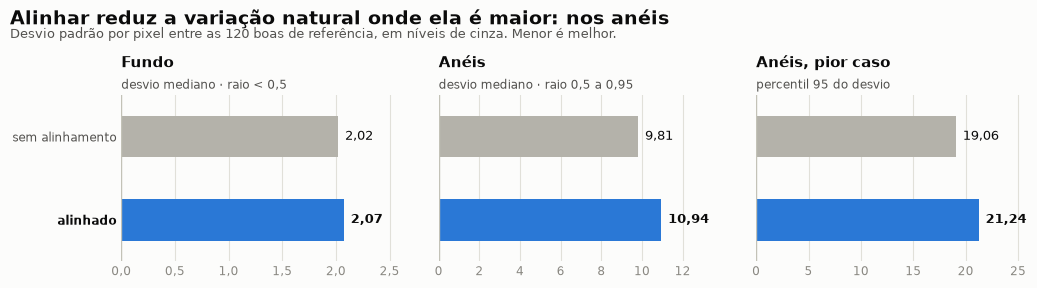

In [ ]:
fundo, aneis = 'fundo (r<0,5)', 'anéis (0,5<=r<0,95)'
fig = viz.hpanels(
    list(tab.index),
    [{'title': 'Fundo', 'note': 'desvio mediano · raio < 0,5', 'values': mediana[fundo]},
     {'title': 'Anéis', 'note': 'desvio mediano · raio 0,5 a 0,95', 'values': mediana[aneis]},
     {'title': 'Anéis, pior caso', 'note': 'percentil 95 do desvio', 'values': p95[aneis]}],
    highlight=1, title='Alinhar reduz a variação natural onde ela é maior: nos anéis',
    subtitle='Desvio padrão por pixel entre as 120 boas de referência, em níveis de cinza. Menor é melhor.')

### 4.2 AUROC de pixel com e sem alinhamento

A AUROC de pixel mede se o mapa z ordena os pixels de defeito acima dos normais, sem depender do limiar. A coluna da avaliação é **registro, não usado para decidir**.

In [ ]:
a = auroc.pivot(index='variante', columns='role', values='auroc_pixel').loc[['sem_alinhamento', 'baseline']]
a.index = ['sem alinhamento', 'baseline (alinhado)']
a.columns.name = None
a = a.rename(columns={'development': 'desenvolvimento (decide)', 'evaluation': 'avaliação (registro, não usado para decidir)'})
viz.fmt_table(a, mark='baseline (alinhado)')

,desenvolvimento (decide),"avaliação (registro, não usado para decidir)"
sem alinhamento,"0,81","0,78"
baseline (alinhado) ← escolhido,"0,83","0,80"


### 4.3 Baseline × sem alinhamento × Otsu por imagem, no desenvolvimento

Médias por imagem nas 9 defeituosas do desenvolvimento (3 por tipo).

In [ ]:
COLS = {'dice_mean': 'Dice', 'iou_mean': 'IoU', 'precision_mean': 'precisão', 'recall_mean': 'recall',
        'n_pred_components_mean': 'componentes por imagem'}
dev = resumo[resumo.role == 'development']
geral = dev.groupby('variante')[list(COLS)].mean().loc[list(VARIANTES)].rename(index=VARIANTES, columns=COLS)  # 3 imagens por tipo: média simples
geral.index.name = None
viz.fmt_table(geral, mark=VARIANTES['baseline'])

,Dice,IoU,precisão,recall,componentes por imagem
baseline (alinhado + limiar calibrado) ← escolhido,"0,52","0,38","0,86","0,40","37,56"
sem alinhamento,"0,49","0,35","0,85","0,37","48,11"
Otsu por imagem,"0,34","0,22","0,92","0,23","19,22"


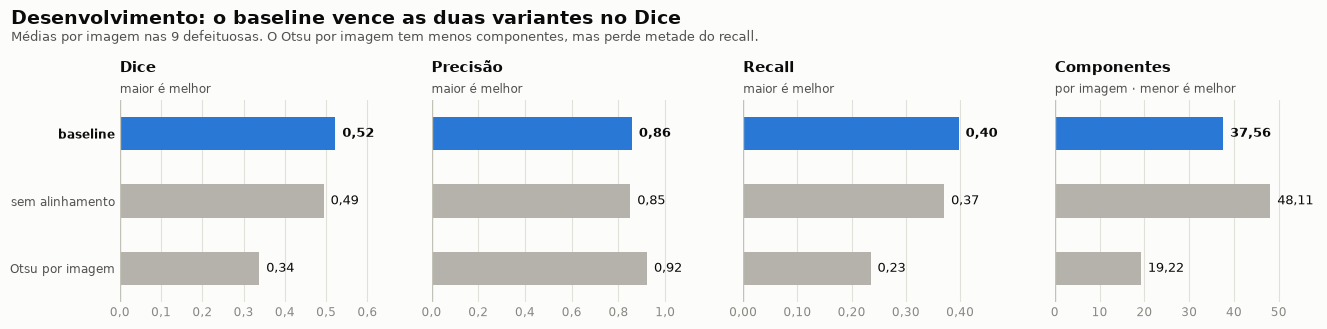

In [ ]:
fig = viz.hpanels(
    ['baseline', 'sem alinhamento', 'Otsu por imagem'],
    [{'title': 'Dice', 'note': 'maior é melhor', 'values': geral['Dice']},
     {'title': 'Precisão', 'note': 'maior é melhor', 'values': geral['precisão']},
     {'title': 'Recall', 'note': 'maior é melhor', 'values': geral['recall']},
     {'title': 'Componentes', 'note': 'por imagem · menor é melhor', 'values': geral['componentes por imagem']}],
    highlight=0, title='Desenvolvimento: o baseline vence as duas variantes no Dice',
    subtitle='Médias por imagem nas 9 defeituosas. O Otsu por imagem tem menos componentes, mas perde metade do recall.')

In [ ]:
# O mesmo, por tipo de defeito
por_tipo = dev.set_index(['variante', 'grupo'])[['dice_mean', 'precision_mean', 'recall_mean', 'n_pred_components_mean']]
por_tipo = por_tipo.loc[list(VARIANTES)].rename(index=VARIANTES, level=0).rename(columns=COLS)
por_tipo.index.names = ['variante', 'tipo']
viz.fmt_table(por_tipo)

Dice precisão recall  \
variante                               tipo                                  
baseline (alinhado + limiar calibrado) broken_large   0,28     0,76   0,18   
                                       broken_small   0,58     0,93   0,42   
                                       contamination  0,71     0,88   0,59   
sem alinhamento                        broken_large   0,24     0,75   0,15   
                                       broken_small   0,55     0,90   0,39   
                                       contamination  0,70     0,89   0,57   
Otsu por imagem                        broken_large   0,16     0,84   0,10   
                                       broken_small   0,36     1,00   0,22   
                                       contamination  0,49     0,93   0,38   

                                                     componentes por imagem  
variante                               tipo                                  
baseline (alinhado + limiar calibrado) broken_large                   42,00  
                                       broken_small                   33,67  
                                       contamination                  37,00  
sem alinhamento                        broken_large                   51,33  
                                       broken_small                   49,67  
                                       contamination                  43,33  
Otsu por imagem                        broken_large                   22,33  
                                       broken_small                    8,67  
                                       contamination                  26,67

### 4.4 Registro da avaliação — **não usado para decidir**

Os mesmos números no conjunto de avaliação ficam registrados como linha de base dos experimentos finais. Nenhum parâmetro foi escolhido olhando para esta tabela. As boas aparecem separadas por origem (achado da Fase 2); nelas não existe Dice, só pixels falsos positivos e componentes espúrios.

In [ ]:
ev = resumo[resumo.role == 'evaluation'].set_index(['variante', 'grupo'])
ev = ev[['n', 'dice_mean', 'precision_mean', 'recall_mean', 'fp_frac_mean', 'n_pred_components_mean']]
ev = ev.assign(fp_frac_mean=100 * ev.fp_frac_mean).loc[list(VARIANTES)].rename(index=VARIANTES, level=0)
ev.columns = ['n', 'Dice', 'precisão', 'recall', 'pixels FP (% da garrafa)', 'componentes por imagem']
ev.index.names = ['variante', 'grupo']
viz.fmt_table(ev)

n  Dice precisão  \
variante                               grupo                              
baseline (alinhado + limiar calibrado) broken_large   17  0,27     0,80   
                                       broken_small   19  0,40     0,70   
                                       contamination  18  0,57     0,72   
                                       good_test      20     –        –   
                                       good_train     59     –        –   
sem alinhamento                        broken_large   17  0,23     0,74   
                                       broken_small   19  0,37     0,66   
                                       contamination  18  0,55     0,70   
                                       good_test      20     –        –   
                                       good_train     59     –        –   
Otsu por imagem                        broken_large   17  0,22     0,88   
                                       broken_small   19  0,26     0,79   
                                       contamination  18  0,53     0,73   
                                       good_test      20     –        –   
                                       good_train     59     –        –   

                                                     recall  \
variante                               grupo                  
baseline (alinhado + limiar calibrado) broken_large    0,17   
                                       broken_small    0,30   
                                       contamination   0,52   
                                       good_test          –   
                                       good_train         –   
sem alinhamento                        broken_large    0,14   
                                       broken_small    0,27   
                                       contamination   0,51   
                                       good_test          –   
                                       good_train         –   
Otsu por imagem                        broken_large    0,15   
                                       broken_small    0,25   
                                       contamination   0,56   
                                       good_test          –   
                                       good_train         –   

                                                     pixels FP (% da garrafa)  \
variante                               grupo                                    
baseline (alinhado + limiar calibrado) broken_large                      0,85   
                                       broken_small                      0,71   
                                       contamination                     0,83   
                                       good_test                         0,92   
                                       good_train                        0,44   
sem alinhamento                        broken_large                      1,01   
                                       broken_small                      0,87   
                                       contamination                     0,92   
                                       good_test                         0,80   
                                       good_train                        0,45   
Otsu por imagem                        broken_large                      1,70   
                                       broken_small                      4,40   
                                       contamination                     6,18   
                                       good_test                        24,73   
                                       good_train                       26,68   

                                                     componentes por imagem  
variante                               grupo                                 
baseline (alinhado + limiar calibrado) broken_large                   39,76  
                                       broken_small                   39,37  
                 

### 4.5 Os 9 exemplos do desenvolvimento no baseline

Colunas: imagem alinhada, mapa z (saturado em 2× o limiar), máscara prevista e ground truth.

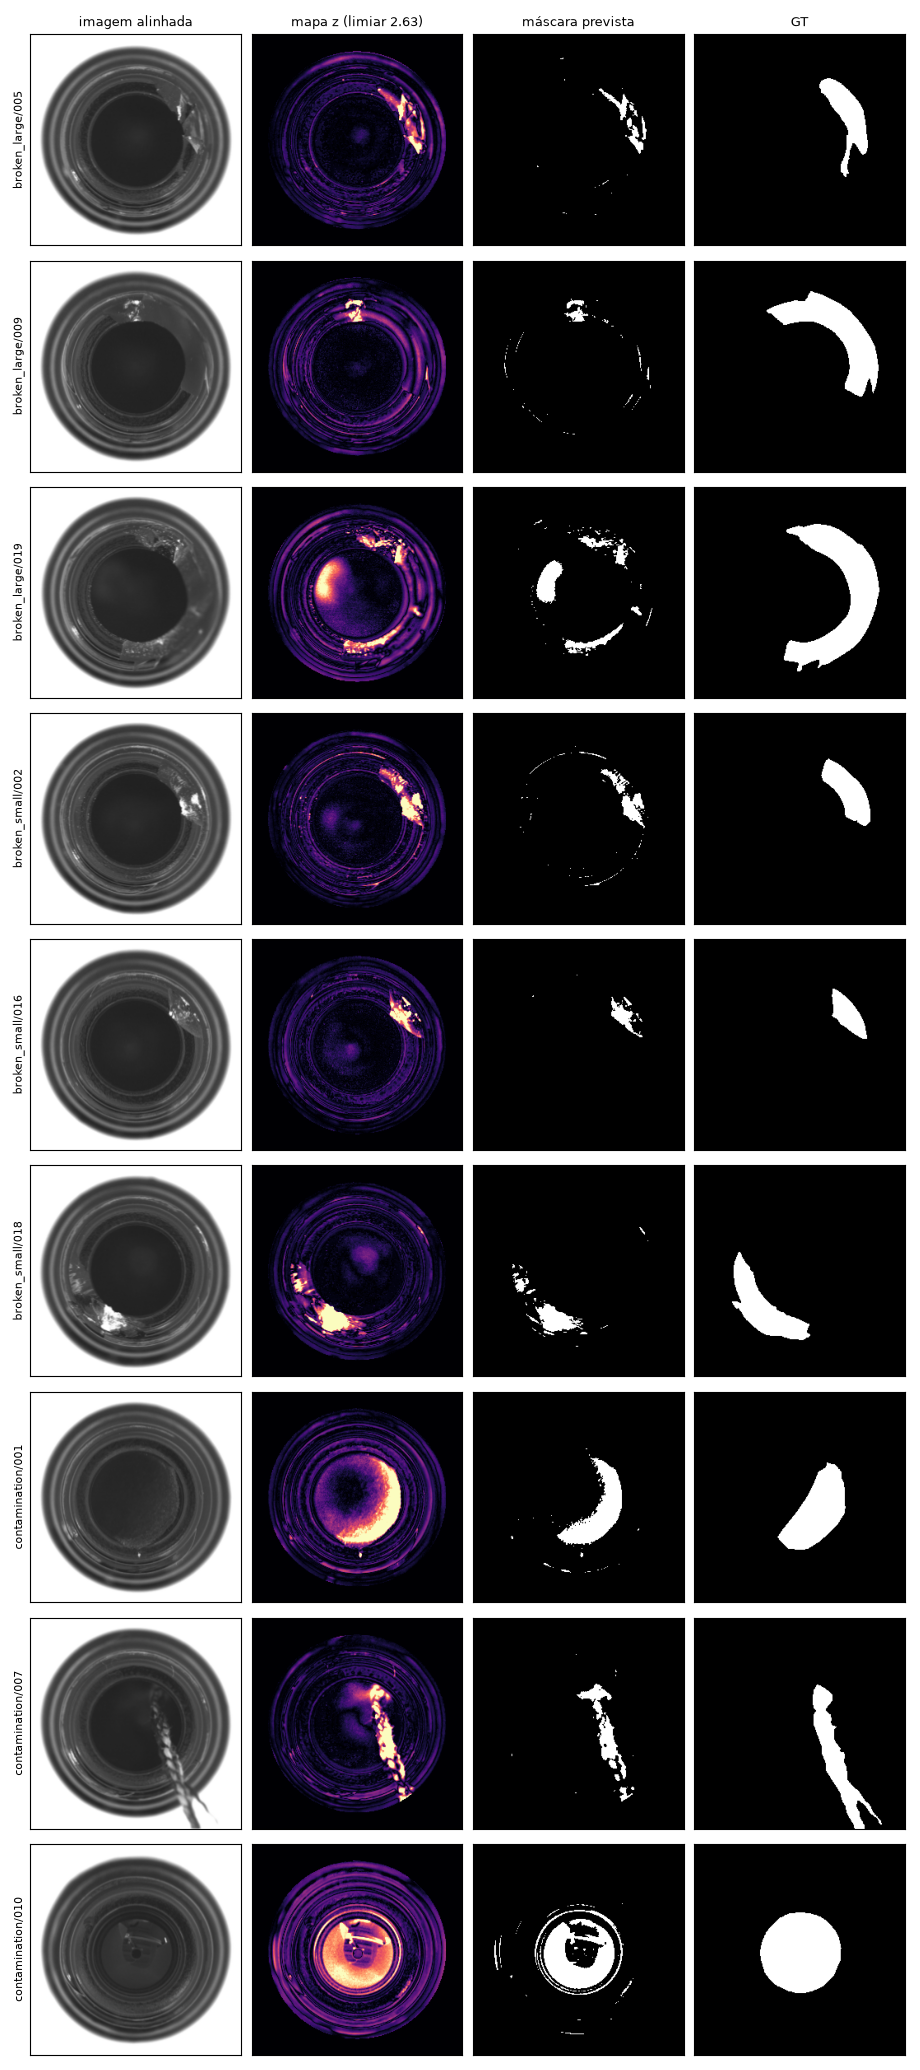

In [ ]:
display(Image(res / 'exemplos_desenvolvimento.png'))

### Exemplo visual (opcional, precisa do dataset)

Refaz só o modelo de referência para mostrar μ e σ por pixel das 120 boas alinhadas. Sem o dataset, a célula avisa e é pulada.

Centro alvo: (127,77; 127,96) px | raio da garrafa: 113,8 px


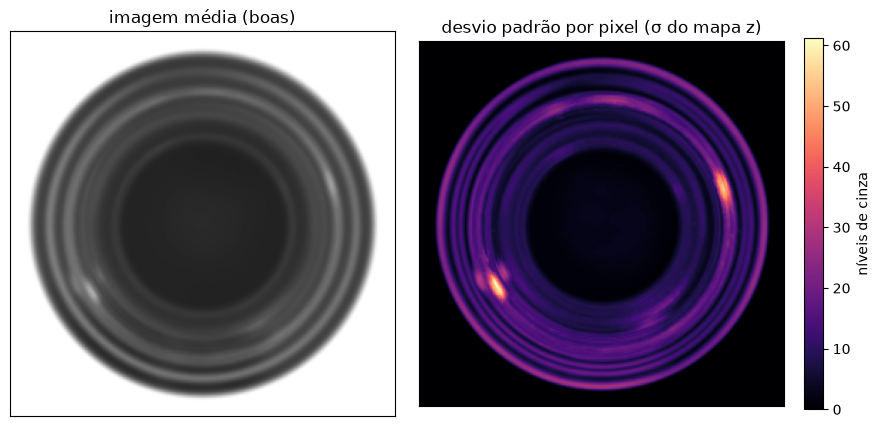

In [ ]:
if viz.dataset_available(cfg['category_dir']):
    import contextlib, io
    import numpy as np
    from pdi_defeitos.pipeline import load_dataset
    from pdi_defeitos.reference import ReferenceModel

    with contextlib.redirect_stderr(io.StringIO()):  # esconde a barra de progresso
        ds = load_dataset(cfg)
    pilha = np.stack([ds.aligned(ds.gray[s], s) for s in ds.ids('reference')])
    modelo = ReferenceModel.fit(pilha, ds.target, ds.radius, cfg['reference']['roi_frac'], cfg['reference']['eps'])
    print(f'Centro alvo: ({viz.fmt_br(ds.target[0])}; {viz.fmt_br(ds.target[1])}) px | raio da garrafa: {viz.fmt_br(ds.radius, 1)} px')
    fig = viz.variability_maps(modelo.mean, modelo.std, 'desvio padrão por pixel (σ do mapa z)')

## 5. Leitura e decisão

**Alinhamento: manter.** O desvio mediano nos anéis cai ~10% (10,94 → 9,81 níveis) e o fundo quase não muda (2,07 → 2,02), como previsto. No desenvolvimento, a AUROC de pixel sobe de 0,81 para 0,83, o Dice de 0,49 para 0,52 e os componentes por imagem caem de 48 para 38. O ganho é pequeno, mas vai na mesma direção em todas as medidas e o alinhamento custa uma translação por imagem.

**Otsu por imagem: descartado.** No desenvolvimento o Dice cai de 0,52 para 0,34 e o recall de 0,40 para 0,23, nos três tipos. O registro da avaliação (não usado para decidir) mostra a causa prevista na hipótese: nas garrafas boas o Otsu marca ~25% da garrafa, contra menos de 1% do limiar calibrado. Sem um modelo do normal, o limiar não sabe quando não há defeito.

**Baseline fixado:** alinhamento por translação + mapa z + limiar no percentil 99,5 das boas de calibração (z ≥ 2,63). Os parâmetros são os da seção `reference` do `config.yaml` (`align: true`, `roi_frac: 0.95`, `eps: 2.0`, `threshold_percentile: 99.5`), mostrados no item 3.

**O que o baseline revela:**

- Precisão alta (0,76 a 0,93) e recall baixo (0,18 a 0,59): o que ele marca quase sempre é defeito, mas ele perde a maior parte do defeito.
- `contamination` é o tipo mais fácil (Dice 0,71), como previa a hipótese 1 da Fase 1: fica no fundo, a região estável.
- O mais difícil é `broken_large` (Dice 0,28), não `broken_small` (0,58), o que contraria a hipótese 2 da Fase 1 no desenvolvimento. Nas quebras grandes, só a parte clara da fratura passa do limiar.
- Fragmentação: 34 a 42 componentes por imagem, a maioria arcos finos nos anéis.

## 6. Como isso orienta a próxima fase

- Os falsos positivos são arcos finos nos anéis, sinal de desalinhamento residual de 1 a 2 px. **Fase 4, denoising:** testar se um passa-baixa reduz essa diferença espúria sem apagar o defeito.
- O recall baixo nas quebras sugere que a intensidade sozinha não basta. **Fase 4, bordas:** quebras criam bordas que não existem na garrafa normal; testar o gradiente (Sobel) e o Canny como informação complementar.
- Este baseline é a régua: toda mudança da Fase 4 é medida contra ele, com o mesmo protocolo.